# 09 - Resultado

## Importar librerías

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
from textwrap import shorten
import matplotlib.pyplot as plt
import seaborn as sns

## Mejorar la visualización

In [2]:
# Que muestre todas las columnas
pd.options.display.max_columns = None
# En los dataframes, mostrar los float con dos decimales
pd.options.display.float_format = '{:,.2f}'.format

In [3]:
sns.set_style('whitegrid')

## Establecer las rutas

In [4]:
RAIZ = Path.cwd().resolve()
for carpeta in [RAIZ, *RAIZ.parents]:
    if (carpeta / 'requirements.txt').is_file() and (carpeta / 'data').is_dir():
        RAIZ = carpeta
        break
else:
    raise FileNotFoundError('Abra el notebook desde el proyecto.')

PROCESSED = RAIZ / 'data/processed'
REPORTS = RAIZ / 'data/reports/09_resultado'
REPORTS.mkdir(parents = True, exist_ok = True)

## Cargar el modelo y el umbral de 08

In [5]:
bundle = joblib.load(PROCESSED / 'ml/modelos/random_forest.joblib')
modelo = bundle['rf_model']
predictores = bundle['predictores']
ajuste = pd.read_csv(RAIZ / 'data/reports/08_modelo_ml/comparacion_umbral.csv', float_precision = 'round_trip')
# La última fila de calibración contiene el umbral ajustado guardado en 08.
umbral_rf = float(ajuste.loc[ajuste['Partición'].eq('Calibración'), 'Umbral'].iloc[-1])
assert list(modelo.classes_) == [0, 1] and len(predictores) == 15
print(f'Umbral de Random Forest: {umbral_rf:.6f}')

Umbral de Random Forest: 0.233094


## Seleccionar los pares con brecha positiva en 2024

In [6]:
base_ml = pd.read_parquet(PROCESSED / 'ml/base_ml_08_1_knn.parquet', columns = [
    'hs6', 'nombre_producto_hs6_baci', 'iso3_d', 'nombre_pais_destino', 'year',
    *predictores, 'trade_value_usd', 'exportaciones_estimadas_usd', 'brecha_usd', 'brecha_relativa'])
datos = base_ml.loc[base_ml['year'].eq(2024) & base_ml['brecha_usd'].gt(0)
    & base_ml['brecha_relativa'].gt(0) & base_ml['exportaciones_estimadas_usd'].gt(0)].copy()
assert not datos.duplicated(['hs6', 'iso3_d', 'year']).any()
assert np.isfinite(datos[predictores].to_numpy()).all()
datos.shape

(87011, 24)

## Calcular el puntaje de Random Forest

In [7]:
datos['prob_reduccion_rf'] = modelo.predict_proba(
    datos[predictores].astype(bundle['tipo_numerico']).to_numpy())[:, 1]
datos['supera_umbral'] = datos['prob_reduccion_rf'].ge(umbral_rf)
columnas = ['hs6', 'nombre_producto_hs6_baci', 'iso3_d', 'nombre_pais_destino',
    'year', 'prob_reduccion_rf', 'supera_umbral', 'trade_value_usd',
    'exportaciones_estimadas_usd', 'brecha_usd', 'brecha_relativa']
puntajes = datos[columnas].sort_values(['prob_reduccion_rf', 'brecha_usd', 'trade_value_usd', 'hs6', 'iso3_d'],
    ascending = [False, False, False, True, True], kind = 'stable').reset_index(drop = True)
print('Pares con brecha positiva:', len(puntajes))
print('Pares que superan el umbral:', int(puntajes['supera_umbral'].sum()))

Pares con brecha positiva: 87011
Pares que superan el umbral: 63105


## Ordenar los pares producto - destino señalados

In [8]:
# Orden de pares del antiguo 10: puntaje, brecha, comercio y códigos.
ranking_pares = puntajes.loc[puntajes['supera_umbral']].copy().reset_index(drop = True)
ranking_pares.insert(0, 'ranking_par', range(1, len(ranking_pares) + 1))
ranking_pares.head(20)

,ranking_par,hs6,nombre_producto_hs6_baci,iso3_d,nombre_pais_destino,year,prob_reduccion_rf,supera_umbral,trade_value_usd,exportaciones_estimadas_usd,brecha_usd,brecha_relativa
0,1,420292,"Cases and containers: n.e.c. in heading 4202, ...",USA,Estados Unidos de América,2024,0.79,True,"702,108.00","1,592,316.86","890,208.86",0.56
1,2,060319,"Flowers, cut: flowers and buds of a kind suita...",MDA,República de Moldova,2024,0.76,True,"33,468.00","59,210.65","25,742.65",0.43
2,3,700992,"Glass mirrors: framed, excluding rear-view mir...",USA,Estados Unidos de América,2024,0.76,True,"73,162.00","141,155.34","67,993.34",0.48
3,4,681599,Stone articles and articles of other mineral s...,USA,Estados Unidos de América,2024,0.75,True,"127,614.00","656,273.47","528,659.47",0.81
4,5,610230,"Coats: women's or girls' overcoats, car-coats,...",USA,Estados Unidos de América,2024,0.75,True,"86,984.00","158,500.97","71,516.97",0.45
5,6,391739,"Plastics: tubes, pipes and hoses thereof, n.e....",USA,Estados Unidos de América,2024,0.74,True,"24,441.00","65,027.56","40,586.56",0.62
6,7,640299,"Footwear: n.e.c. in heading no. 6402, (other t...",USA,Estados Unidos de América,2024,0.73,True,"906,919.00","1,294,369.57","387,450.57",0.30
7,8,060311,"Flowers, cut: roses, flowers and buds of a kin...",MEX,México,2024,0.73,True,"3,508.00","20,153,124.00","20,149,616.00",1.00
8,9,060319,"Flowers, cut: flowers and buds of a kind suita...",MEX,México,2024,0.73,True,"92,384.00","19,391,380.08","19,298,996.08",1.00
9,10,640419,"Footwear: (other than sportswear), with outer ...",USA,Estados Unidos de América,2024,0.73,True,"685,643.00","850,898.12","165,255.12",0.19


## Conservar el destino con mayor puntaje para cada producto

In [9]:
contexto = puntajes.groupby('hs6', as_index = False).agg(
    destinos_con_brecha = ('iso3_d', 'nunique'), destinos_senalados = ('supera_umbral', 'sum'),
    brecha_total_positiva_usd = ('brecha_usd', 'sum'))
# El mejor destino se elige con el orden de pares del antiguo 10.
ranking_productos = ranking_pares.drop_duplicates('hs6').drop(columns = 'ranking_par').merge(
    contexto, on = 'hs6', validate = 'one_to_one')
ranking_productos = ranking_productos.sort_values(
    ['prob_reduccion_rf', 'brecha_total_positiva_usd', 'brecha_usd', 'hs6'],
    ascending = [False, False, False, True], kind = 'stable').reset_index(drop = True)
ranking_productos.insert(0, 'ranking_producto', range(1, len(ranking_productos) + 1))
print('Productos señalados:', len(ranking_productos))
ranking_productos.head(20)

Productos señalados: 3862


,ranking_producto,hs6,nombre_producto_hs6_baci,iso3_d,nombre_pais_destino,year,prob_reduccion_rf,supera_umbral,trade_value_usd,exportaciones_estimadas_usd,brecha_usd,brecha_relativa,destinos_con_brecha,destinos_senalados,brecha_total_positiva_usd
0,1,420292,"Cases and containers: n.e.c. in heading 4202, ...",USA,Estados Unidos de América,2024,0.79,True,"702,108.00","1,592,316.86","890,208.86",0.56,91,76,"3,005,951.49"
1,2,060319,"Flowers, cut: flowers and buds of a kind suita...",MDA,República de Moldova,2024,0.76,True,"33,468.00","59,210.65","25,742.65",0.43,96,85,"205,914,178.92"
2,3,700992,"Glass mirrors: framed, excluding rear-view mir...",USA,Estados Unidos de América,2024,0.76,True,"73,162.00","141,155.34","67,993.34",0.48,42,34,"186,598.30"
3,4,681599,Stone articles and articles of other mineral s...,USA,Estados Unidos de América,2024,0.75,True,"127,614.00","656,273.47","528,659.47",0.81,42,39,"1,326,713.00"
4,5,610230,"Coats: women's or girls' overcoats, car-coats,...",USA,Estados Unidos de América,2024,0.75,True,"86,984.00","158,500.97","71,516.97",0.45,46,35,"283,144.97"
5,6,391739,"Plastics: tubes, pipes and hoses thereof, n.e....",USA,Estados Unidos de América,2024,0.74,True,"24,441.00","65,027.56","40,586.56",0.62,41,32,"117,344.25"
6,7,640299,"Footwear: n.e.c. in heading no. 6402, (other t...",USA,Estados Unidos de América,2024,0.73,True,"906,919.00","1,294,369.57","387,450.57",0.30,65,56,"2,347,930.30"
7,8,060311,"Flowers, cut: roses, flowers and buds of a kin...",MEX,México,2024,0.73,True,"3,508.00","20,153,124.00","20,149,616.00",1.00,90,81,"222,380,214.97"
8,9,640419,"Footwear: (other than sportswear), with outer ...",USA,Estados Unidos de América,2024,0.73,True,"685,643.00","850,898.12","165,255.12",0.19,75,69,"1,550,138.55"
9,10,392630,"Plastics: fittings for furniture, coachwork or...",USA,Estados Unidos de América,2024,0.72,True,"18,942.00","81,109.47","62,167.47",0.77,29,25,"139,843.60"


## Graficar los veinte primeros productos

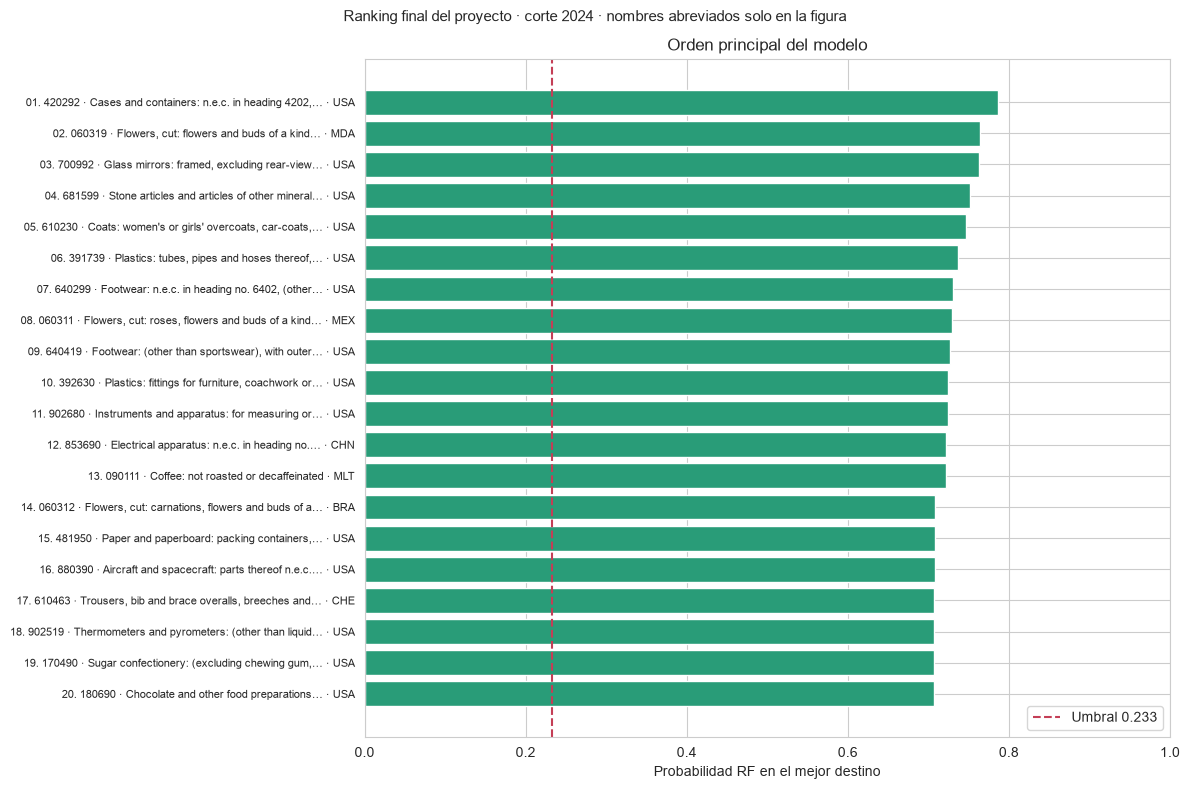

In [10]:
top = ranking_productos.head(20).iloc[::-1]
etiquetas = top.apply(lambda fila: f"{fila['ranking_producto']:02d}. {fila['hs6']} · "
    f"{shorten(fila['nombre_producto_hs6_baci'], width = 48, placeholder = '…')} · {fila['iso3_d']}", axis = 1)
plt.figure(figsize = (12, 8))
plt.barh(etiquetas, top['prob_reduccion_rf'], color = '#299c78')
plt.axvline(umbral_rf, color = '#c43e56', linestyle = '--', label = f'Umbral {umbral_rf:.3f}')
plt.xlim(0, 1)
plt.xlabel('Probabilidad RF en el mejor destino')
plt.title('Orden principal del modelo')
plt.suptitle('Ranking final del proyecto · corte 2024 · nombres abreviados solo en la figura', fontsize = 11)
plt.yticks(fontsize = 8)
plt.legend(loc = 'lower right')
plt.tight_layout()
plt.savefig(REPORTS / 'ranking_productos.png', dpi = 180, bbox_inches = 'tight')
plt.show()

## Guardar los puntajes y los rankings

In [11]:
puntajes.to_parquet(REPORTS / 'puntajes_2024.parquet', index = False)
ranking_pares.to_csv(REPORTS / 'ranking_pares.csv', index = False)
ranking_productos.to_csv(REPORTS / 'ranking_productos.csv', index = False)
print('Resultados guardados en:', REPORTS.relative_to(RAIZ))

Resultados guardados en: data\reports\09_resultado
